# 📘 11.3 Solving Elliptic Partial Differential Equations

Unlike **parabolic PDEs**, which typically describe how a system evolves over time and can be solved by advancing from known initial conditions, **elliptic PDEs** generally describe spatial *boundary-value* problems, and this is often associated with steady-state behaviour.

Their numerical solution therefore requires a different approach: rather than marching forward in time, we must determine the unknown values throughout the spatial domain while satisfying the governing equation and boundary conditions.

A common numerical approach is to **discretise the spatial domain**, approximate the derivatives using **finite differences**, and assemble the resulting algebraic equations into a **system of linear equations**. This system can then be solved using direct or iterative methods, including the relaxation techniques introduced previously in Week 10.

In this notebook, we will develop this general solution procedure using the **five-point finite-difference stencil** applied to a two-dimensional steady-state heat-conduction problem. We will then explore how boundary conditions, numerical convergence and grid resolution influence the solution.

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * **Explain** why an elliptic boundary-value problem is solved differently from a time-marching parabolic PDE.
> * **Construct** the five-point finite-difference approximation of the two-dimensional Laplace equation.
> * **Map** unknown grid temperatures into a vector and **assemble** the matrix system $A\mathbf T=\mathbf b$, including known boundary contributions.
> * **Solve and compare** direct, Jacobi and Gauss–Seidel (Liebmann) methods.
> * **Modify** the assembled equations for an insulated (Neumann) edge and recognise how other boundary conditions affect the system.
> * **Check** discrete residuals, compare meshes and interpret temperatures and heat flux without confusing numerical agreement with physical validation.

## 📂 11.3.0 How to use this notebook

This notebook builds on finite-difference derivatives, boundary-value problems, the classification of PDEs and the idea of iterative relaxation. The essential new task is to **assemble and solve a two-dimensional spatial system**.

Follow the calculations in this order:

1. **Sketch the plate/domain geometry and its boundary values**; identify the unknown interior nodes.
2. **Apply a stencil** around one node.
3. **Translate each stencil equation into a row** of $A\mathbf T=\mathbf b$.
4. **Solve and check** the system, then change the boundary conditions or source term.

Start with the diagrams and the complete matrix system before running the first solver. Later code examples in this notebook will reuse the same problem so that the effect of each numerical change is easy to see.

## 📂 11.3.1 From time marching to a spatial boundary-value problem

A previously studied example is the parabolic diffusion equation (for constant diffusivity $D$):

$$\frac{\partial T}{\partial t}=D\left(\frac{\partial^2T}{\partial x^2}+\frac{\partial^2T}{\partial y^2}\right).$$

An explicit time-marching method such as FTCS calculates $T^{n+1}$ from a known field $T^n$ and requires an **initial condition**. If the temperature stops changing with time, and there is no internal heat generation, the governing equation reduces to

$$\boxed{\frac{\partial^2T}{\partial x^2}+\frac{\partial^2T}{\partial y^2}=0.}$$

This is **Laplace's equation**, a standard elliptic PDE. The unknown is the *steady spatial field* $T(x,y)$, which is determined by the PDE and appropriate conditions around the boundary.

We do not have an initial temperature field to march forward from; instead, we solve the coupled spatial equations. Iterating a solver toward that solution is a numerical procedure and does **not** represent physical elapsed time.

> **Connection to 1D boundary-value problems:** Solving $y''=f(x)$ subject to values at two ends already required several coupled unknowns. Here the same idea extends to a **two-dimensional grid**, where each unknown typically interacts with four neighbouring nodes.

## 📂 11.3.2 Sketch the elliptic problem: the plate and node indices

Consider a thin square plate of width $L=0.40\,\mathrm{m}$, with **constant thermal conductivity** $k$, negligible temperature variation through its thickness and **no internal heat generation**. Its four edges have prescribed temperatures:

- **Left edge:** $75\,^\circ\mathrm C$.
- **Right edge:** $50\,^\circ\mathrm C$.
- **Bottom edge:** $0\,^\circ\mathrm C$.
- **Top edge:** $100\,^\circ\mathrm C$.

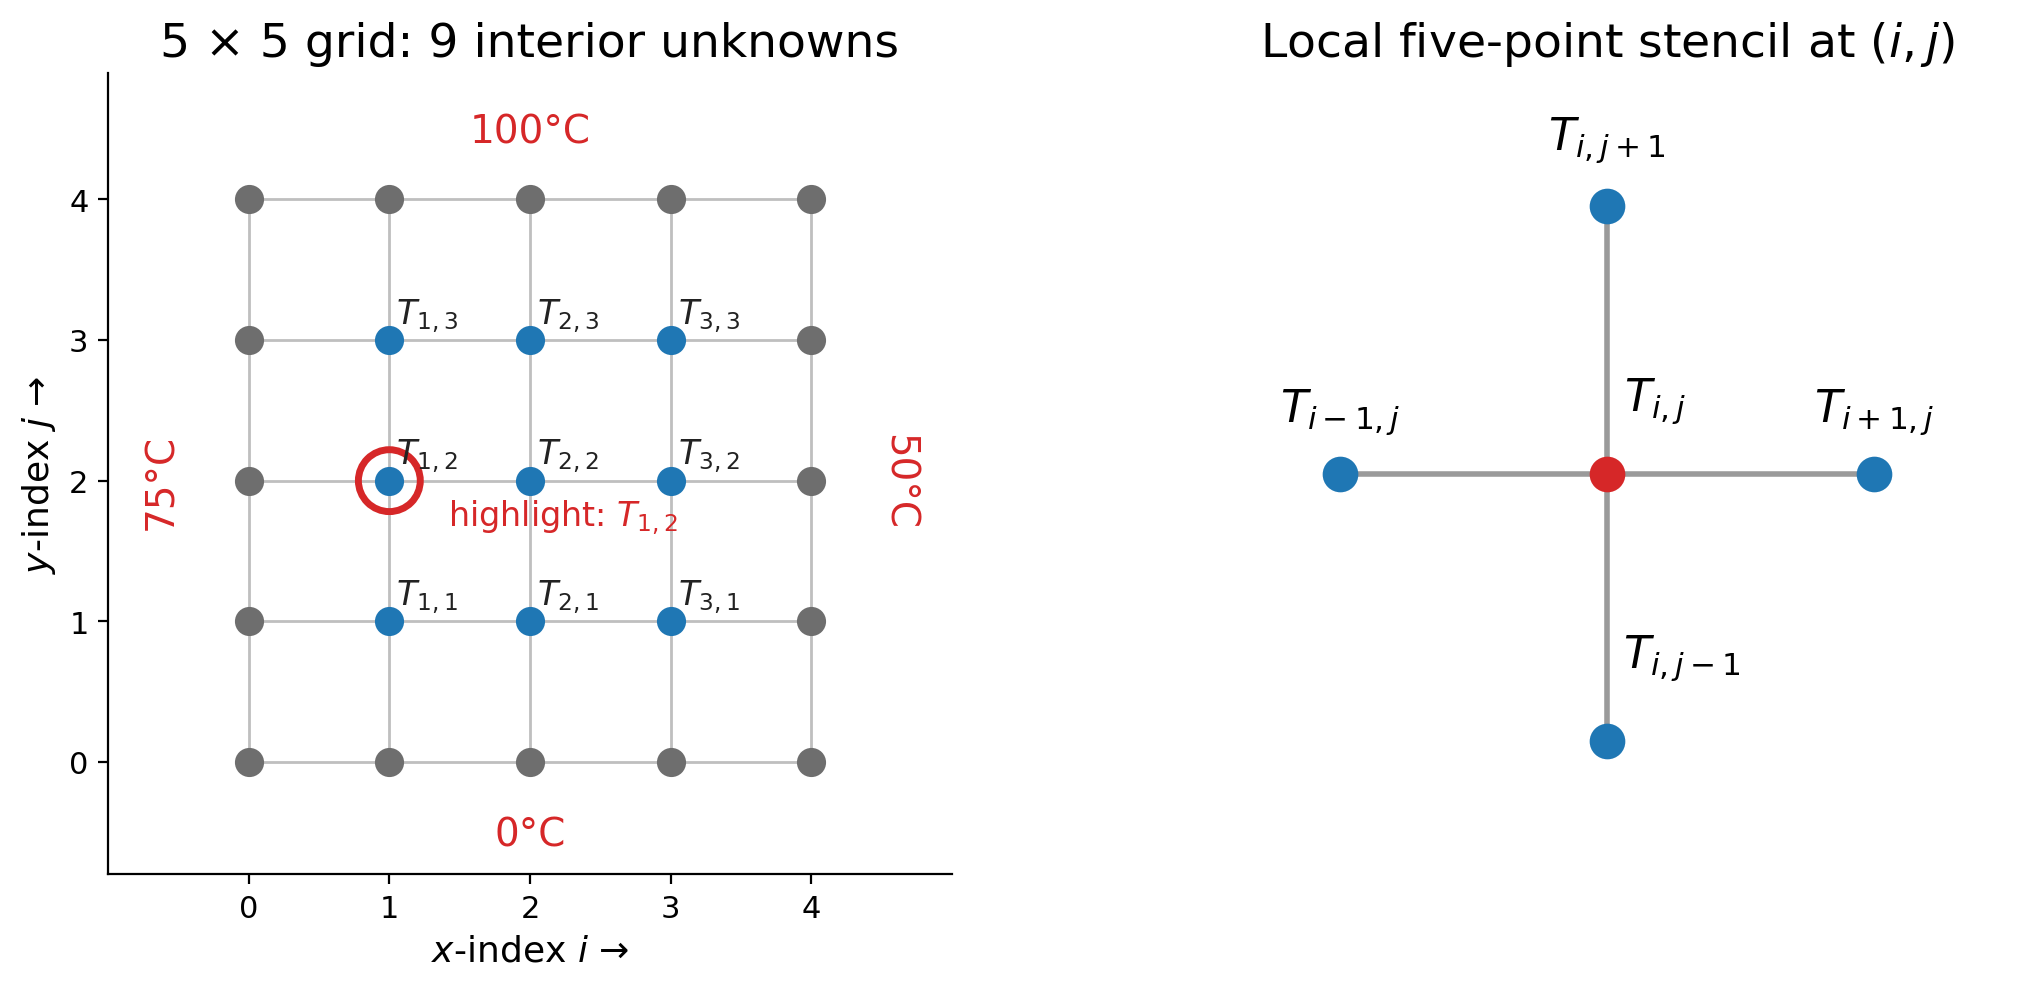

Under these assumptions, steady energy conservation and Fourier's law $\mathbf q=-k\nabla T$ lead to **Laplace's equation** in the interior:

$$\nabla^2T=\frac{\partial^2T}{\partial x^2}+\frac{\partial^2T}{\partial y^2}=0.$$

We divide the plate into **four equal intervals along each axis**, giving **five grid nodes along $x$ and five along $y$**. The nine nodes strictly inside the boundary are unknown.

### How to read $T_{i,j}$

The ordered pair $(i,j)$ identifies a **location on the spatial grid**, not two different temperatures:

- The **first index $i$** identifies the $x$ location, counting **left to right**: $i=0,1,2,3,4$.
- The **second index $j$** identifies the $y$ location, counting **bottom to top**: $j=0,1,2,3,4$.
- For example, **$T_{1,2}$** lies at the **second grid node in $x$** ($i=1$) and the **third grid node in $y$** ($j=2$), since counting starts at zero on the boundaries. This is highlighted in the figure above.

Thus $T_{1,2}$ is **not** interchangeable with $T_{2,1}$. The figure above highlights $T_{1,2}$ and shows all nine unknown interior nodes. At corner points where two different fixed-temperature edges meet, the edge values will conflict; the corner values are not used by our interior five-point equations.


## 📂 11.3.3 From the grid to the five-point stencil

On the right-hand side of the diagram above, we show how we isolate one interior node $(i,j)$ and its four neighbours: left/right in $x$ and below/above in $y$. We approximate the two second derivatives using centred finite differences on an equally spaced grid, $\Delta x=\Delta y=h$:

$$\frac{\partial^2T}{\partial x^2}\approx\frac{T_{i-1,j}-2T_{i,j}+T_{i+1,j}}{h^2},\qquad
\frac{\partial^2T}{\partial y^2}\approx\frac{T_{i,j-1}-2T_{i,j}+T_{i,j+1}}{h^2}.$$

Substitute both into Laplace's equation and multiply through by $h^2$:

$$\boxed{4T_{i,j}-T_{i-1,j}-T_{i+1,j}-T_{i,j-1}-T_{i,j+1}=0.}\tag{11.3}$$

This is the **five-point stencil**. It applies to **each of the nine interior nodes**. Every interior temperature is coupled to its four neighbours. If a neighbour is a boundary node, its temperature is **already known**; move that contribution to the right-hand side when assembling the system.

## 📂 11.3.4 Assemble the full system $A\mathbf T=\mathbf b$

Apply the five-point stencil at **every interior node**. First, organise the nine unknown temperatures into one vector, ordered **left to right along the lowest interior row, then upward**:

$$\mathbf T=[T_{1,1},T_{2,1},T_{3,1},\;T_{1,2},T_{2,2},T_{3,2},\;T_{1,3},T_{2,3},T_{3,3}]^\mathsf T.$$

For $n$ interior nodes in each direction, the associated **zero-based Python vector index** is

$$r=(j-1)n+(i-1),\qquad i,j=1,\ldots,n.$$

**Indexing distinction:** mathematical subscripts use $(i,j)$ = (**$x$**, **$y$**),

whereas a NumPy temperature array is stored as `field[j, i]` = **[row, column]**. The vector index $r$ converts the interior grid location into one row/column of $A$.

### Worked node: $(i,j)=(1,1)$

This is the **bottom-left interior node**. Its left neighbour is the **75°C boundary** and its lower neighbour is the **0°C boundary**, so

$$4T_{1,1}-75-T_{2,1}-0-T_{1,2}=0$$

becomes

$$\boxed{4T_{1,1}-T_{2,1}-T_{1,2}=75.}$$

In the chosen order of unknowns, that equation becomes row 1 of $A\mathbf T=\mathbf b$:

$$
\begin{bmatrix}
4 & -1 & 0 & -1 & 0 & 0 & 0 & 0 & 0
\end{bmatrix}
\mathbf{T}=75.
$$

### Worked node: $(i,j)=(2,2)$

The centre node has **four unknown interior neighbours** and therefore **no contribution from a prescribed edge temperature**:

$$4T_{2,2}-T_{1,2}-T_{3,2}-T_{2,1}-T_{2,3}=0.$$

This becomes row 5 of the matrix, with $b_5=0$. In general, **each matrix row corresponds to one interior node**, with diagonal coefficient $4$, neighbour coefficients $-1$, and boundary contributions placed in $\mathbf b$.

### Complete $9\times9$ matrix for the heated plate

**Check before running the code:** the top-left unknown $T_{1,3}$ touches both the 75°C left edge and the 100°C top edge, so its entry in $\mathbf b$ is $75+100=175$; by contrast, the centre node has $b_5=0$.

Putting all nine stencil equations together gives the system that the first Python solver will compute:

$$\boxed{\underbrace{\begin{bmatrix}
4&-1&0&-1&0&0&0&0&0\\
-1&4&-1&0&-1&0&0&0&0\\
0&-1&4&0&0&-1&0&0&0\\
-1&0&0&4&-1&0&-1&0&0\\
0&-1&0&-1&4&-1&0&-1&0\\
0&0&-1&0&-1&4&0&0&-1\\
0&0&0&-1&0&0&4&-1&0\\
0&0&0&0&-1&0&-1&4&-1\\
0&0&0&0&0&-1&0&-1&4
\end{bmatrix}}_{A}\,\underbrace{\begin{bmatrix}T_{1,1}\\T_{2,1}\\T_{3,1}\\T_{1,2}\\T_{2,2}\\T_{3,2}\\T_{1,3}\\T_{2,3}\\T_{3,3}\end{bmatrix}}_{\mathbf T}=\underbrace{\begin{bmatrix}75\\0\\50\\75\\0\\50\\175\\100\\150\end{bmatrix}}_{\mathbf b}.}$$

Coefficient matrix A:
[[ 4 -1  0 -1  0  0  0  0  0]
 [-1  4 -1  0 -1  0  0  0  0]
 [ 0 -1  4  0  0 -1  0  0  0]
 [-1  0  0  4 -1  0 -1  0  0]
 [ 0 -1  0 -1  4 -1  0 -1  0]
 [ 0  0 -1  0 -1  4  0  0 -1]
 [ 0  0  0 -1  0  0  4 -1  0]
 [ 0  0  0  0 -1  0 -1  4 -1]
 [ 0  0  0  0  0 -1  0 -1  4]]

Right-hand-side vector b:
[ 75   0  50  75   0  50 175 100 150]

Interior temperatures [°C]:
[[42.86 33.26 33.93]
 [63.17 56.25 52.46]
 [78.57 76.12 69.64]]

Maximum absolute residual: 2.84e-14


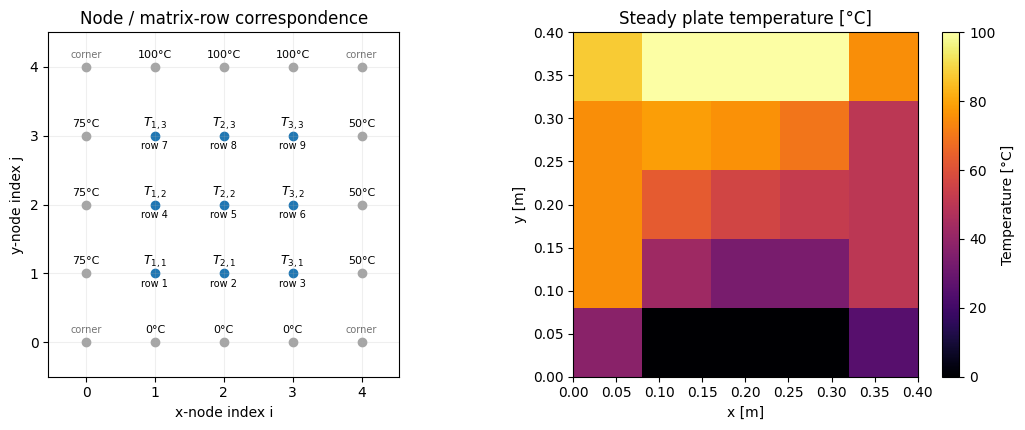

In [ ]:
# @title 💻 Example 1: Assemble and directly solve the nine-node system

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. DEFINE THE PHYSICAL PROBLEM AND BOUNDARY CONDITIONS
# ============================================================

L = 0.40  # Width and height of the square plate [m]

def make_fixed_plate(n, generation=0.0, conductivity=20.0):
    """
    Assemble A and b for a 2D steady-state heat conduction problem.

    n: Number of INTERIOR nodes along each direction.
    generation: Internal heat generation [W/m³], zero for Laplace.
    conductivity: Thermal conductivity [W/(m K)].

    Returns A, b, boundary field and grid spacing h.
    """

    # There are n interior nodes and 2 boundary nodes per direction.
    h = L / (n + 1)

    # Store temperature as edge[j, i]:
    #   i corresponds to the x-direction (columns)
    #   j corresponds to the y-direction (rows)
    edge = np.zeros((n + 2, n + 2))

    # Prescribed Dirichlet boundary temperatures [°C]
    edge[1:-1, 0]  = 75.0    # Left edge
    edge[1:-1, -1] = 50.0    # Right edge
    edge[0, 1:-1]  = 0.0     # Bottom edge
    edge[-1, 1:-1] = 100.0   # Top edge

    # Corner values are assigned only for plotting.
    # They are not used in the interior finite-difference equations.
    edge[0, 0], edge[0, -1] = 37.5, 25.0
    edge[-1, 0], edge[-1, -1] = 87.5, 75.0

    # ========================================================
    # 2. ASSEMBLE THE LINEAR SYSTEM A @ T = b
    # ========================================================

    # Convert the 2D index (i,j) to a 1D matrix row index.
    # Python indexing starts at 0, while our interior nodes
    # are labelled i,j = 1,2,...,n.
    #
    # For n=3:
    # T(1,1) -> row 0, T(2,1) -> row 1, T(3,1) -> row 2
    # T(1,2) -> row 3, and so on.
    def number(i, j):
        return (j - 1) * n + (i - 1)

    # Each interior node contributes one unknown and one equation.
    # Therefore, n*n unknowns require an (n*n) x (n*n) matrix.
    A = np.zeros((n*n, n*n))
    b = np.zeros(n*n)

    # Apply the five-point stencil at every interior node.
    for j in range(1, n + 1):         # Move upwards in y
        for i in range(1, n + 1):     # Move rightwards in x

            row = number(i, j)

            # Five-point stencil:
            # 4*T(i,j) - T(left) - T(right) - T(bottom) - T(top) = 0

            # Coefficient of the central unknown T(i,j)
            A[row, row] = 4.0

            # Coordinates of the four neighbouring nodes
            neighbours = [
                (i-1, j),  # Left
                (i+1, j),  # Right
                (i, j-1),  # Bottom
                (i, j+1)   # Top
            ]

            for ii, jj in neighbours:

                if 1 <= ii <= n and 1 <= jj <= n:
                    # Interior neighbour: its temperature is unknown.
                    # Add its coefficient (-1) to matrix A.
                    A[row, number(ii, jj)] -= 1.0

                else:
                    # Boundary neighbour: its temperature is known.
                    # Move it to the right-hand-side vector b.
                    b[row] += edge[jj, ii]

            # Optional source term for the Poisson equation.
            # This equals zero for the present Laplace problem.
            b[row] += generation * h**2 / conductivity

    return A, b, edge, h


# ============================================================
# 3. SOLVE THE LINEAR SYSTEM DIRECTLY
# ============================================================

n = 3  # 3 x 3 interior nodes = 9 unknown temperatures

A, b, edge, h = make_fixed_plate(n)

# Display the assembled linear system.
print("Coefficient matrix A:")
print(A.astype(int))

print("\nRight-hand-side vector b:")
print(b.astype(int))

# Solve A @ T = b using a direct linear algebra solver.
# This returns a 1D vector of the nine unknown temperatures.
T_direct = np.linalg.solve(A, b)

print("\nInterior temperatures [°C]:")
print(np.round(T_direct.reshape(n, n), 2))

# Check how accurately the computed solution satisfies A @ T = b.
residual = np.linalg.norm(A @ T_direct - b, ord=np.inf)
print(f"\nMaximum absolute residual: {residual:.2e}")


# ============================================================
# 4. RECONSTRUCT THE 2D TEMPERATURE FIELD
# ============================================================

def restore_field(interior, edge):
    """Place the solved interior temperatures into the full grid."""

    field = edge.copy()  # Retain the known boundary temperatures
    n = edge.shape[0] - 2

    # Reshape the 1D solution vector into a 2D array.
    # Rows correspond to increasing j; columns to increasing i.
    field[1:-1, 1:-1] = interior.reshape(n, n)

    return field

T_fixed = restore_field(T_direct, edge)


# ============================================================
# 5. VISUALISE THE GRID AND TEMPERATURE DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

# --- (a) Grid nodes and their corresponding matrix rows ---

ax = axes[0]

for j in range(n + 2):
    for i in range(n + 2):

        is_interior = (1 <= i <= n) and (1 <= j <= n)

        ax.scatter(i, j, color="tab:blue" if is_interior else "0.65")

        if is_interior:
            # Label the unknown temperature and its equation number.
            ax.text(i, j + 0.12, rf"$T_{{{i},{j}}}$",
                    ha="center", fontsize=9)

            ax.text(i, j - 0.20, f"row {(j-1)*n+i}",
                    ha="center", fontsize=7)

        elif (i in (0, n+1)) and (j in (0, n+1)):
            ax.text(i, j + 0.13, "corner",
                    ha="center", fontsize=7, color="0.45")

        else:
            # Prescribed boundary temperature
            ax.text(i, j + 0.13, f"{edge[j,i]:.0f}°C",
                    ha="center", fontsize=8)

ax.set(
    xlim=(-0.55, n+1.55),
    ylim=(-0.50, n+1.50),
    xlabel="x-node index i",
    ylabel="y-node index j",
    title="Node / matrix-row correspondence"
)
ax.set_xticks(range(n+2))
ax.set_yticks(range(n+2))
ax.set_aspect("equal")
ax.grid(alpha=0.2)


# --- (b) Reconstructed steady-state temperature field ---

ax = axes[1]

image = ax.imshow(
    T_fixed,
    origin="lower",        # j increases upwards
    extent=[0, L, 0, L],   # Physical dimensions [m]
    cmap="inferno"
)

ax.set(
    xlabel="x [m]",
    ylabel="y [m]",
    title="Steady plate temperature [°C]"
)

fig.colorbar(image, ax=ax, label="Temperature [°C]")

plt.tight_layout()
plt.show()


The first row printed from the Python matrix should match the **hand-worked equation** above, and the full printed vector $\mathbf b$ should match the nine prescribed-boundary contributions. Because this illustrative system is small, `np.linalg.solve` is convenient; the plotted temperature field is reconstructed from the nine interior unknowns plus the edge values.

**Convergence and performance:** the small residual $\|A\mathbf T-\mathbf b\|_\infty$ measures how closely the solution satisfies the **discrete equations**. It does not measure spatial discretisation error. The matrix is mostly zeros (sparse), although we intentionally store it as a dense NumPy array for readability. As the grid is refined, the number of unknowns increases rapidly; for larger systems, sparse storage and appropriate linear solvers are usually more efficient in both memory and computation. We will compare iterative convergence against this direct result next.

## 📂 11.3.5 Direct solution versus relaxation

Relaxation methods were introduced earlier for one-dimensional boundary-value problems. The **same algebraic idea** works for the $2$D plate: rather than solving all rows at once, repeatedly update the interior values from neighbouring estimates. For the Laplace stencil:

$$T_{i,j}^{(k+1)}=\frac{T_{i-1,j}^{(*)}+T_{i+1,j}^{(*)}+T_{i,j-1}^{(*)}+T_{i,j+1}^{(*)}}{4}.$$

* **Jacobi:** every starred value comes from the **previous** iteration $k$; compute a completely new vector before replacing the old one.
* **Gauss–Seidel (Liebmann's method):** immediately reuse **new** values from the current sweep when available .

Both methods are solving the **same** $A\mathbf T=\mathbf b$. For this Dirichlet Laplace problem, the standard Dirichlet Laplace matrix has favourable properties for these iterations; both converge in this problem, although a finer grid generally takes more iterations.

A useful stopping rule is a small **equation residual**, $\|A\mathbf T^{(k)}-\mathbf b\|_\infty<\varepsilon$. The residual has units of temperature here because we multiplied Laplace's equation by $h^2$ when building $A$. A small *change between iterations* alone can be misleading if the solver has not actually satisfied the equations.


Jacobi: 73 sweeps, residual=8.19e-10, max difference from direct=8.19e-10 °C
Gauss-Seidel: 38 sweeps, residual=8.53e-10, max difference from direct=4.26e-10 °C


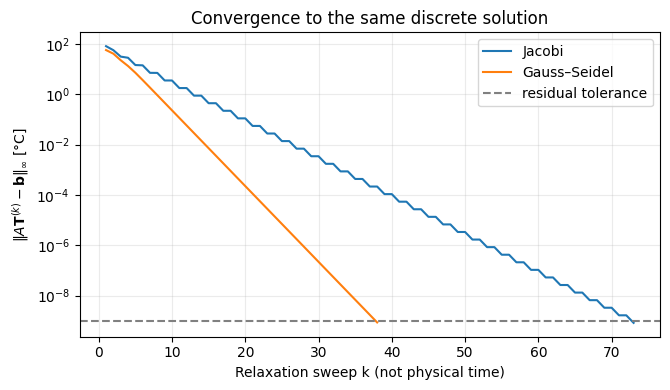

In [ ]:
# @title 💻 Example 2: Jacobi and Gauss–Seidel solve the same matrix

# ============================================================
# 1. DEFINE THE ITERATIVE RELAXATION SOLVER
# ============================================================

def relax(A, b, method, tolerance=1e-9, max_sweeps=5000):

    # Start with an initial numerical guess (all unknowns = 0).
    # This is NOT an initial condition in physical time.
    x = np.zeros_like(b)
    diagonal = np.diag(A)
    history = []

    # Repeat until the solution converges or the limit is reached.
    for sweep in range(1, max_sweeps + 1):

        if method == "Jacobi":
            # Update all unknowns using values from the previous sweep.
            # The entire vector x is replaced simultaneously.
            x = x + (b - A @ x) / diagonal

        elif method == "Gauss-Seidel":
            # Update unknowns one at a time, immediately reusing
            # newly calculated values within the same sweep.
            for row in range(len(b)):
                other_terms = A[row] @ x - A[row, row] * x[row]
                x[row] = (b[row] - other_terms) / diagonal[row]

        else:
            raise ValueError("method must be 'Jacobi' or 'Gauss-Seidel'")

        # Check convergence using the maximum absolute equation residual.
        residual = np.linalg.norm(A @ x - b, ord=np.inf)
        history.append(residual)

        if residual < tolerance:
            return x, np.array(history)

    raise RuntimeError(f"{method} did not meet the residual tolerance")


# ============================================================
# 2. COMPARE THE ITERATIVE AND DIRECT SOLUTIONS
# ============================================================

# Solve the same system A @ T = b from Example 1.
T_jacobi, r_jacobi = relax(A, b, "Jacobi")
T_gs, r_gs = relax(A, b, "Gauss-Seidel")

for label, vec, residuals in (
    ("Jacobi", T_jacobi, r_jacobi),
    ("Gauss-Seidel", T_gs, r_gs)
):
    # Compare iteration counts, final residuals and solution differences.
    print(f"{label}: {len(residuals)} sweeps, "
          f"residual={residuals[-1]:.2e}, "
          f"max difference from direct={np.max(np.abs(vec-T_direct)):.2e} °C")

    # Verify agreement with the direct solution from Example 1.
    assert np.allclose(vec, T_direct, atol=1e-7)


# ============================================================
# 3. VISUALISE THE CONVERGENCE HISTORY
# ============================================================

plt.figure(figsize=(6.8, 4.0))

# Plot residual after each complete relaxation sweep.
plt.semilogy(np.arange(1, len(r_jacobi)+1), r_jacobi, label="Jacobi")
plt.semilogy(np.arange(1, len(r_gs)+1), r_gs, label="Gauss–Seidel")

# Both methods stop when their residual falls below this threshold.
plt.axhline(1e-9, color="0.5", ls="--", label="residual tolerance")

plt.xlabel("Relaxation sweep k (not physical time)")
plt.ylabel(r"$\Vert A\mathbf{T}^{(k)}-\mathbf{b}\Vert_\infty$ [°C]")
plt.title("Convergence to the same discrete solution")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


> **Interpretation:** The direct solver and the two relaxation methods should agree within the chosen residual tolerance. **Iteration count** measures numerical work, not how long the physical plate takes to reach thermal equilibrium. Gauss–Seidel requires fewer sweeps in this example, but fewer sweeps do not automatically mean a faster implementation. Larger grids generally need more relaxation sweeps; more sophisticated sparse solvers or successive overrelaxation (SOR) may be useful for demanding problems.

## 📂 11.3.6 Boundary conditions change the matrix equations

Four common boundary-condition types are Dirichlet, Neumann, Robin and periodic. For an elliptic PDE, the essential question is:

**Which grid-node values remain unknown, and what algebraic equations enforce the boundary?**

* **Dirichlet (fixed temperature):** known edge values enter $\mathbf b$. The edge values are **not** additional unknowns in Example 1.
* **Neumann (specified normal derivative or heat flux):** a boundary value may remain **unknown** and must be included in the solve. We can enforce the derivative through a **ghost point**, using a centred finite difference.
* **Robin (temperature–flux combination):** contributes a boundary equation involving both wall temperature and normal gradient; its coefficients alter the boundary rows.
* **Periodic:** opposite edges are coupled (wrap-around matrix entries) rather than being assigned independent fixed values.

### 🔹 Insulated lower edge (Neumann condition)

Change **only the lower edge** of the previous plate from $T(x,0)=0$ to insulation:

$$\left.\frac{\partial T}{\partial y}\right|_{y=0}=0.\tag{11.4}$$

At a bottom boundary node $j=0$, the centred derivative gives

$$\frac{T_{i,1}-T_{i,-1}}{2h}=0\quad\Longrightarrow\quad T_{i,-1}=T_{i,1}.$$

Use this ghost value in the five-point equation **at the bottom boundary node itself**:

$$\boxed{4T_{i,0}-T_{i-1,0}-T_{i+1,0}-2T_{i,1}=0.}\tag{11.5}$$

The bottom-node temperatures $T_{1,0},T_{2,0},T_{3,0}$ are now **unknowns**. Our system grows from $9\times9$ to **$12\times12$**, because the three bottom-edge temperatures must also be solved for. We continue imposing the PDE on bottom nodes excluding the corners; the left, right and top edges retain their original Dirichlet data. The resulting matrix need not be symmetric with this ghost-node treatment.

With insulation: matrix shape = (12, 12)
Unknown bottom-edge temperatures [°C] = [71.91 67.01 59.54]
Centre temperature: fixed bottom = 56.25 °C; insulated bottom = 72.84 °C
Mixed-BC residual = 1.14e-13


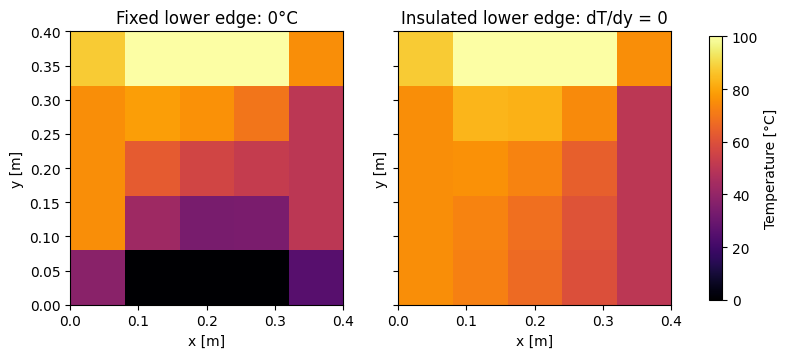

In [ ]:
# @title 💻 Example 3: Insulated bottom edge using ghost nodes

# ============================================================
# 1. ASSEMBLE THE SYSTEM WITH AN INSULATED BOTTOM BOUNDARY
# ============================================================

def make_insulated_bottom(n):
    """Assemble Laplace's equation with an insulated bottom edge."""

    # The bottom boundary (j=0) now contains unknown temperatures.
    # Unknown rows are j=0,1,...,n, giving n*(n+1) unknowns.
    def number(i, j):
        return j * n + (i - 1)

    A_mix = np.zeros((n*(n+1), n*(n+1)))
    b_mix = np.zeros(n*(n+1))

    for j in range(n+1):
        for i in range(1, n+1):

            row = number(i, j)
            A_mix[row, row] = 4.0  # Central stencil coefficient

            # LEFT AND RIGHT: Dirichlet boundary conditions
            if i == 1:
                b_mix[row] += 75.0  # Known left temperature
            else:
                A_mix[row, number(i-1, j)] -= 1.0

            if i == n:
                b_mix[row] += 50.0  # Known right temperature
            else:
                A_mix[row, number(i+1, j)] -= 1.0

            # BOTTOM: Neumann boundary condition (insulated)
            if j == 0:
                # Zero heat flux: dT/dy = 0
                # Centred difference: T[i,1] - T[i,-1] = 0
                # Therefore, ghost node T[i,-1] = T[i,1].
                #
                # In the five-point stencil, the two vertical
                # neighbours combine into -2*T[i,1].
                # The ghost node is ELIMINATED, not stored in A.
                A_mix[row, number(i, 1)] -= 2.0

            else:
                # Ordinary interior stencil: bottom neighbour
                A_mix[row, number(i, j-1)] -= 1.0

                # TOP: Dirichlet boundary condition
                if j == n:
                    b_mix[row] += 100.0
                else:
                    A_mix[row, number(i, j+1)] -= 1.0

    return A_mix, b_mix


# ============================================================
# 2. SOLVE AND RECONSTRUCT THE TEMPERATURE FIELD
# ============================================================

A_mix, b_mix = make_insulated_bottom(n)
T_unknown_mix = np.linalg.solve(A_mix, b_mix)

# Reconstruct the full grid using the boundaries from Example 1.
T_insulated = edge.copy()

# First n values: unknown temperatures along the insulated edge.
T_insulated[0, 1:-1] = T_unknown_mix[:n]

# Remaining values: the n x n interior temperatures.
T_insulated[1:-1, 1:-1] = T_unknown_mix[n:].reshape(n, n)

# The bottom corners retain the fixed left/right temperatures.
T_insulated[0, 0], T_insulated[0, -1] = 75.0, 50.0

print("With insulation: matrix shape =", A_mix.shape)
print("Unknown bottom-edge temperatures [°C] =",
      np.round(T_unknown_mix[:n], 2))

print("Centre temperature: fixed bottom =",
      round(T_fixed[2, 2], 2),
      "°C; insulated bottom =",
      round(T_insulated[2, 2], 2), "°C")

# Check that the computed temperatures satisfy the modified system.
residual = np.linalg.norm(A_mix @ T_unknown_mix - b_mix, np.inf)
print("Mixed-BC residual =", f"{residual:.2e}")

# Numerical reference check for the n=3 example.
if n == 3:
    assert np.allclose(T_unknown_mix[:3],
                       [71.91, 67.01, 59.54], atol=0.02)


# ============================================================
# 3. COMPARE THE TWO BOUNDARY-CONDITION CASES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(9.7, 3.8),
                         sharex=True, sharey=True)

# Use the same colour scale to compare temperature distributions.
for ax, values, title in zip(
    axes,
    (T_fixed, T_insulated),
    ("Fixed lower edge: 0°C", "Insulated lower edge: dT/dy = 0")
):
    image = ax.imshow(
        values, origin="lower", extent=(0, L, 0, L),
        vmin=0, vmax=100, cmap="inferno"
    )
    ax.set(title=title, xlabel="x [m]", ylabel="y [m]")

fig.colorbar(image, ax=axes, label="Temperature [°C]", shrink=0.9)
plt.show()


The insulated lower boundary imposes a zero normal temperature gradient. Hence,the three bottom-edge temperatures are now **unknown** rather than fixed at 0°C.

For the numerical values in this example, they should be approximately **71.91, 67.01 and 59.54°C** from left to right. The residual check confirms that the 12 × 12 algebraic system is satisfied to numerical precision.

**An important qualification:** A problem with *only* Neumann boundaries may have a solution determined only up to an additive constant (or may be incompatible with the prescribed fluxes). A Laplace problem that is periodic in every direction has a similar constant-offset freedom. The fixed edges in this mixed-BC example remove that ambiguity.

## 📂 11.3.7 Numerical checks: residuals and grid refinement

These three different questions should not be confused:

1. **Discrete residual:** does the computed vector satisfy $A\mathbf T=\mathbf b$?
2. **Solver convergence:** do Jacobi and Gauss–Seidel approach the same discrete answer as the direct solve?
3. **Grid convergence:** does the computed field change as the spatial spacing $h$ is reduced?

The earlier examples already report the residual and compare different matrix solvers.


### 🔹 Example 4 — Grid Refinement

Example 4 below specifically tests grid sensitivity: it solves the same fixed-boundary Laplace problem on progressively finer meshes and compares temperatures at the same physical locations, which are  x=y=L/2  and  x=y=L/4 .

The centre value at  x=y=L/2  happens to remain unchanged in this particular problem because of the chosen boundary temperatures and symmetry. So, let's look at the off-centre value  x=y=L/4  as a more useful refinement indicator.

Also, the prescribed edge temperatures disagree at the corners, so this example should not be used to claim a uniform global  O(h2)  convergence rate without further analysis.

In [ ]:
# @title 💻 Example 4A: Grid refinement of the fixed-boundary Laplace plate

# ============================================================
# 1. SOLVE THE SAME PROBLEM USING DIFFERENT GRID RESOLUTIONS
# ============================================================

grid_sizes = [3, 7, 15]  # Interior nodes along each direction

h_values = []
T_centre_values = []
T_quarter_values = []

print("Grid refinement for the fixed-boundary Laplace plate:\n")

for count in grid_sizes:

    # Assemble and directly solve the system on the current grid.
    A_h, b_h, edge_h, h_h = make_fixed_plate(count)
    T_h = np.linalg.solve(A_h, b_h)

    # Reconstruct the full temperature field, including boundaries.
    field_h = restore_field(T_h, edge_h)

    # Identify grid indices corresponding to fixed physical positions.
    # These locations are grid nodes for all selected resolutions.
    centre = (count + 1) // 2     # x = y = L/2
    quarter = (count + 1) // 4    # x = y = L/4

    # Read the temperatures at these two monitoring points.
    # Array indexing follows [j, i] = [y-index, x-index].
    T_centre = field_h[centre, centre]
    T_quarter = field_h[quarter, quarter]

    # Store the results for the convergence plots.
    h_values.append(h_h)
    T_centre_values.append(T_centre)
    T_quarter_values.append(T_quarter)

    print(f"{count:2d} × {count:2d} interior nodes, "
          f"h = {h_h:.4f} m: "
          f"T(L/2,L/2) = {T_centre:.4f} °C; "
          f"T(L/4,L/4) = {T_quarter:.4f} °C")

    # Retain the finest-grid field for the next visualisation.
    if count == grid_sizes[-1]:
        T_fine = field_h
        x_fine = np.linspace(0, L, count + 2)


Grid refinement for the fixed-boundary Laplace plate:

 3 ×  3 interior nodes, h = 0.1000 m: T(L/2,L/2) = 56.2500 °C; T(L/4,L/4) = 42.8571 °C
 7 ×  7 interior nodes, h = 0.0500 m: T(L/2,L/2) = 56.2500 °C; T(L/4,L/4) = 42.6710 °C
15 × 15 interior nodes, h = 0.0250 m: T(L/2,L/2) = 56.2500 °C; T(L/4,L/4) = 42.6166 °C


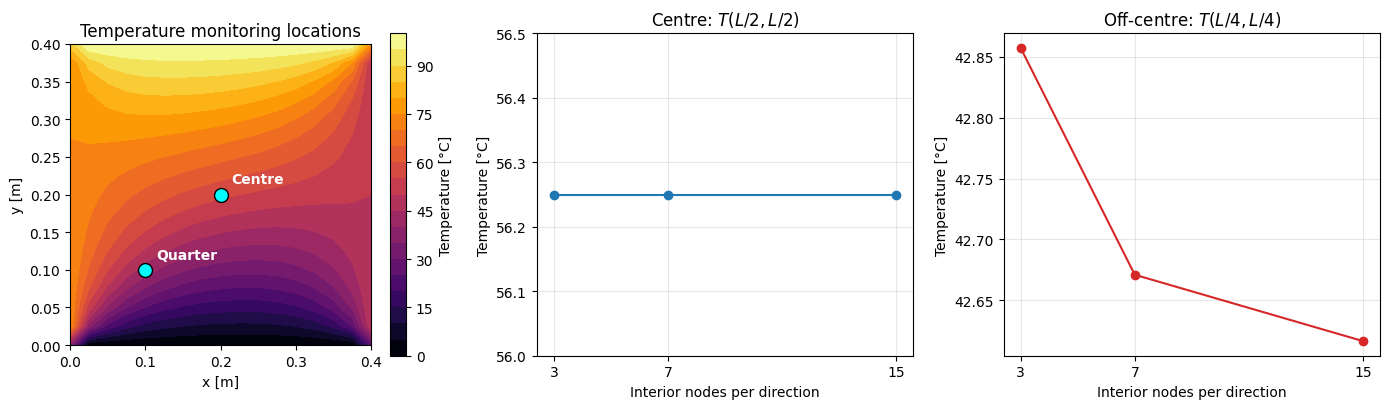

In [ ]:
# @title 📊 Example 4B: Visualising grid refinement and convergence

# ============================================================
# 2. SHOW THE MONITORING LOCATIONS ON THE TEMPERATURE FIELD
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Temperature field from the finest grid (15 x 15 interior nodes)
X, Y = np.meshgrid(x_fine, x_fine)

image = axes[0].contourf(X, Y, T_fine, levels=20, cmap="inferno")

# Mark the two physical locations used for the comparison.
points = [
    (L/2, L/2, "Centre"),
    (L/4, L/4, "Quarter")
]

for x, y, label in points:
    axes[0].scatter(x, y, s=100, color="cyan",
                    edgecolor="black", zorder=5)
    axes[0].annotate(label, (x, y), xytext=(8, 8),
                     textcoords="offset points",
                     color="white", fontweight="bold")

axes[0].set(
    xlabel="x [m]", ylabel="y [m]",
    title="Temperature monitoring locations",
    aspect="equal"
)
fig.colorbar(image, ax=axes[0], label="Temperature [°C]")


# ============================================================
# 3. PLOT TEMPERATURE AGAINST GRID RESOLUTION
# ============================================================

# Centre temperature
axes[1].plot(grid_sizes, T_centre_values, "o-", color="tab:blue")
axes[1].set(
    xlabel="Interior nodes per direction",
    ylabel="Temperature [°C]",
    title=r"Centre: $T(L/2,L/2)$"
)
axes[1].set_ylim(56.0, 56.5)
axes[1].set_xticks(grid_sizes)
axes[1].grid(alpha=0.3)

# Off-centre temperature
axes[2].plot(grid_sizes, T_quarter_values, "o-", color="tab:red")
axes[2].set(
    xlabel="Interior nodes per direction",
    ylabel="Temperature [°C]",
    title=r"Off-centre: $T(L/4,L/4)$"
)
axes[2].set_xticks(grid_sizes)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpreting grid convergence**

As the number of grid nodes increases, the grid spacing $h$ decreases and the finite-difference approximation becomes more refined.

- At the **centre of the plate**, the temperature remains at $56.25^\circ\mathrm{C}$ for all three grids. This is a consequence of the symmetry of this particular problem and does not, by itself, demonstrate grid convergence.
- At the **off-centre point**, the temperature changes from approximately $42.86^\circ\mathrm{C}$ to $42.62^\circ\mathrm{C}$. The progressively smaller changes suggest that the numerical solution is approaching a grid-independent value.

**Key takeaway:** Grid convergence should be assessed by comparing solutions at the same physical locations as the grid is refined. A small change between successive grids provides evidence of convergence, although further refinement or comparison with an analytical solution may be needed to establish numerical accuracy.

### 🔹 Example 5 — Heat flux derived from the temperature field

This is **not another PDE solve**. Once a temperature field has been computed, a useful engineering output is the **conductive heat-flux vector**. For a material with constant conductivity $k$,

$$q_x=-k\frac{\partial T}{\partial x},\qquad q_y=-k\frac{\partial T}{\partial y}.$$

**Example 5** estimates the temperature gradients from the original fixed-boundary solution and reports the heat-flux components at the centre. Because our field is stored as `field[j, i]`, NumPy returns derivatives in the order **$y$ first, then $x$**. The output is in $\mathrm{W/m^2}$.

In [ ]:
# @title 💻 Example 5A: Temperature gradients and conductive heat flux

# ============================================================
# 1. CALCULATE THE TEMPERATURE GRADIENTS
# ============================================================

k_conductivity = 20.0  # Thermal conductivity [W/(m K)]

# Use the finest-grid solution from Example 4.
T_flux = T_fine
h_flux = h_values[-1]

# Approximate spatial derivatives using finite differences.
# Since the array is indexed [j, i], np.gradient returns
# dT/dy first (rows), followed by dT/dx (columns).
dTdy, dTdx = np.gradient(T_flux, h_flux, h_flux)

# ============================================================
# 2. APPLY FOURIER'S LAW: q = -k * grad(T)
# ============================================================

# The negative sign means heat flows towards lower temperature.
qx = -k_conductivity * dTdx
qy = -k_conductivity * dTdy

# Extract heat-flux components at the centre of the plate.
centre = T_flux.shape[0] // 2

qx_c = qx[centre, centre]
qy_c = qy[centre, centre]

q_magnitude = np.hypot(qx_c, qy_c)

print(f"Heat flux at the plate centre (x = y = {L/2:.2f} m):")
print(f"  qx = {qx_c:.1f} W/m²")
print(f"  qy = {qy_c:.1f} W/m²")
print(f"  Magnitude = {q_magnitude:.1f} W/m²")


Heat flux at the plate centre (x = y = 0.20 m):
  qx = 1044.3 W/m²
  qy = -4177.2 W/m²
  Magnitude = 4305.8 W/m²


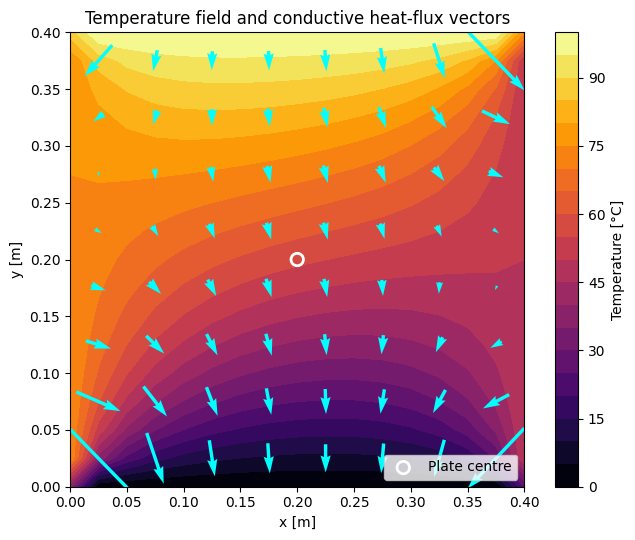

In [ ]:
# @title 📊 Example 5B: Visualising the conductive heat-flux field

# ============================================================
# 3. PREPARE THE SPATIAL GRID
# ============================================================

# Create physical x-y coordinates corresponding to T_flux.
x = np.linspace(0, L, T_flux.shape[1])
y = np.linspace(0, L, T_flux.shape[0])
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(figsize=(7, 5.5))

# Background: temperature distribution across the plate.
image = ax.contourf(X, Y, T_flux, levels=20, cmap="inferno")

# ============================================================
# 4. OVERLAY THE HEAT-FLUX VECTORS
# ============================================================

# Sample every second interior node to avoid crowded arrows.
# Boundary nodes are excluded from the vector plot.
sample = np.s_[1:-1:2, 1:-1:2]

ax.quiver(
    X[sample], Y[sample],
    qx[sample], qy[sample],
    color="cyan", pivot="mid"
)

# Mark the centre where the heat flux was evaluated.
ax.scatter(L/2, L/2, s=80, facecolors="none",
           edgecolors="white", linewidths=2,
           zorder=5, label="Plate centre")

ax.set(
    xlabel="x [m]",
    ylabel="y [m]",
    title="Temperature field and conductive heat-flux vectors"
)
ax.set_aspect("equal")
ax.legend(loc="lower right")

fig.colorbar(image, ax=ax, label="Temperature [°C]")

plt.tight_layout()
plt.show()


The temperature gradient $\nabla T$ points towards increasing temperature, whereas the conductive heat-flux vector $\mathbf{q}=-k\nabla T$ points towards decreasing temperature. The arrows therefore indicate how heat is transported through the plate from hotter regions towards colder regions.

**Key takeaway:** Once the temperature field has been obtained by solving the elliptic PDE, finite differences can also be used to calculate derived physical quantities, such as temperature gradients and heat flux.

**Numerical note:** `np.gradient()` uses central differences at interior nodes and one-sided differences at the domain boundaries by default. The visualisation samples only interior nodes to avoid including the corner values, which were assigned for display purposes rather than determined by the governing equations.

### 🔹 Example 6 — Poisson's equation with internal heat generation

Now **change the physical problem**. Suppose the plate generates heat uniformly at $\dot q=10{,}000\,\mathrm{W/m^3}$ while retaining the same material and all four fixed boundary temperatures. The steady equation becomes **Poisson's equation**:

$$k\nabla^2T+\dot q=0.$$

Using the **same five-point stencil** gives

$$\boxed{4T_{i,j}-T_{i-1,j}-T_{i+1,j}-T_{i,j-1}-T_{i,j+1}=\frac{\dot qh^2}{k}.}$$

For this constant-$k$ example with unchanged grid and Dirichlet edges, **$A$ stays the same**: heat generation adds a source contribution to the right-hand side $\mathbf b$. **Example 6** tests this by recomputing the temperatures and comparing the source-free and internally heated fields.

In [ ]:
# @title 💻 Example 6A: Poisson equation — same matrix, new source term

# ============================================================
# 1. INTRODUCE INTERNAL HEAT GENERATION
# ============================================================

heat_generation = 50_000.0  # Positive volumetric heat generation [W/m³]

# Reuse make_fixed_plate() from Example 1.
# With generation > 0, the same function now assembles
# the Poisson equation instead of the Laplace equation.
#
# Keep the same 3 x 3 interior grid, conductivity and
# boundary conditions as the original Example 1.
A_p, b_p, edge_p, h_p = make_fixed_plate(
    3, generation=heat_generation, conductivity=k_conductivity
)

# ============================================================
# 2. COMPARE THE NEW SYSTEM WITH EXAMPLE 1
# ============================================================

# The five-point stencil is unchanged, so matrix A is identical.
# Only b changes: each equation receives q_dot * h² / k.
source_contribution = heat_generation * h_p**2 / k_conductivity

print("Matrix A unchanged from Example 1:", np.array_equal(A_p, A))
print(f"Added source contribution per equation: {source_contribution:.2f} °C")
print("Difference between new and original RHS vectors:", np.round(b_p - b, 2))

# ============================================================
# 3. SOLVE AND COMPARE THE TEMPERATURES
# ============================================================

# Solve the modified system using the same direct solver.
T_poisson = restore_field(np.linalg.solve(A_p, b_p), edge_p)

# Compare against the original Laplace solution from Example 1.
centre = 2  # Centre index for the full 5 x 5 grid

print(f"\nCentre temperature (Laplace): {T_fixed[centre, centre]:.2f} °C")
print(f"Centre temperature (Poisson): {T_poisson[centre, centre]:.2f} °C")
print(f"Temperature increase: "
      f"{T_poisson[centre, centre] - T_fixed[centre, centre]:.2f} °C")

# Verify that the solution satisfies the Poisson linear system.
residual = np.linalg.norm(
    A_p @ T_poisson[1:-1, 1:-1].ravel() - b_p, ord=np.inf
)
print(f"Poisson-system residual: {residual:.2e}")



Matrix A unchanged from Example 1: True
Added source contribution per equation: 25.00 °C
Difference between new and original RHS vectors: [25. 25. 25. 25. 25. 25. 25. 25. 25.]

Centre temperature (Laplace): 56.25 °C
Centre temperature (Poisson): 84.38 °C
Temperature increase: 28.13 °C
Poisson-system residual: 2.84e-14


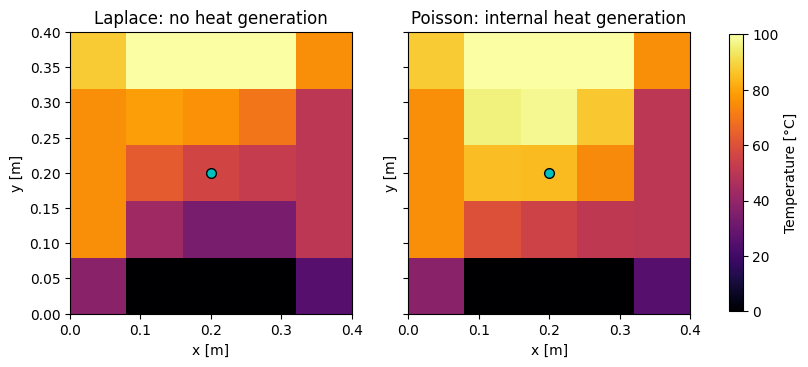

In [ ]:
# @title 📊 Example 6B: Comparing Laplace and Poisson temperature fields

# ============================================================
# 4. COMPARE THE TWO TEMPERATURE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4),
                         sharex=True, sharey=True)

cases = [
    (T_fixed, "Laplace: no heat generation"),
    (T_poisson, "Poisson: internal heat generation")
]

# Use the same colour limits for a meaningful comparison.
T_min = min(T_fixed.min(), T_poisson.min())
T_max = max(T_fixed.max(), T_poisson.max())

for ax, (values, title) in zip(axes, cases):

    image = ax.imshow(
        values, origin="lower", extent=(0, L, 0, L),
        vmin=T_min, vmax=T_max, cmap="inferno"
    )

    # Mark the centre where temperatures were compared.
    ax.plot(L/2, L/2, "co", markersize=7,
            markeredgecolor="black")

    ax.set(
        xlabel="x [m]",
        ylabel="y [m]",
        title=title
    )
    ax.set_aspect("equal")

fig.colorbar(image, ax=axes, label="Temperature [°C]", shrink=0.9)
plt.show()


Introducing internal heat generation changes the governing equation from **Laplace's equation** to **Poisson's equation**. However, because the spatial discretisation, thermal conductivity and boundary conditions remain unchanged, the coefficient matrix $A$ is identical to that in Example 1. Only the right-hand-side vector $\mathbf{b}$ changes to account for the source term.

The resulting temperature field is warmer in the interior of the plate, while the prescribed boundary temperatures remain fixed.

**Key takeaway:** The same finite-difference solution framework can accommodate different physical effects by modifying the assembled equations, without necessarily changing the coefficient matrix or solution method.

# ✅ Key takeaways and practice

* **Parabolic FTCS** advances from an initial condition through **physical time**. A **steady elliptic** problem instead determines a coupled spatial field from its PDE and boundary conditions.
* A five-point stencil at each grid point becomes **one row of a linear system**. Neighbouring unknown temperatures form the matrix coefficients; prescribed temperatures enter the right-hand side.
* **Direct**, **Jacobi** and **Gauss–Seidel/Liebmann** methods solve the same discrete system, but iteration sweeps are not time steps. Report a residual or another justified stopping check.
* A **Neumann** boundary can add unknown edge values and extra equations. A **source term** can modify the right-hand side without changing the matrix for this simple constant-coefficient case.
* **Agreement between solvers is not the same as grid convergence or physical validation.** Investigate both numerical and modelling limitations.

**Try these adjustments:** (i) locate the matrix row for $T_{3,1}$ and identify its known boundary contributions; (ii) change the relaxation tolerance and compare iteration counts; (iii) increase the grid resolution and inspect the off-centre temperature (does the centre value change?); (iv) double the volumetric heat generation and observe the centre temperature. Predict the direction of each change **before** running it.



# 🔗 Bridge to the following notebooks

The next topic will consider the **stability of finite-difference methods**, especially when solving time-dependent PDEs. Keep in mind that **time-step stability**, **convergence of an iterative linear solver** and **grid convergence** are related questions but are not interchangeable. A later notebook will develop the **Crank–Nicolson** approach for time-dependent diffusion, where a matrix solve is required at each physical time step.

# 📚 References and source notes (optional further reading)


* Chapra, S. C. and Canale, R. P., *Numerical Methods for Engineers*, 8th ed., Chapter 29: Laplace and Poisson equations, five-point differences, Liebmann's method and derivative boundary conditions.
* LeVeque, R. J., *Finite Difference Methods for Ordinary and Partial Differential Equations*, SIAM (2007), Chapter 3 and §4.1: two-dimensional stencil, matrix ordering and iterative methods.



# 🤖 AI Acknowledgment
This teaching notebook was drafted with assistance from ChatGPT 5.6 (OpenAI) and Google Gemini, for proofreading and for assistance in the creation of the flat-plate elliptic solution code example in Python. These Python examples were executed, and numerical results were checked for accuracy and meaning. All outputs from the LLM were proofread and edited by the teaching team (YCV) before final release.